<a href="https://colab.research.google.com/github/sjadhav7279-boop/AI-ML-Assignments/blob/main/Assignment3(sanjeevani).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

df = pd.read_csv('/mnt/data/sanjeevani_diabetes_screening_raw.csv', dtype=str)

print("Shape:", df.shape)

print("\nRaw column names:")
for col in df.columns:
    print(repr(col))

print("\nDistinct values of Sex:")
print(df['Sex'].unique())

print("\nDistinct values of family_history:")
print(df['family_history'].unique())

print("\nDistinct values of HbA1c Result:")
print(df['HbA1c Result '].unique())

Shape: (3038, 13)

Raw column names:
'Patient ID'
'Camp Location'
'Sex'
'Age'
'family_history'
'height_cm'
'weight_kg'
'BMI'
'waist_cm'
'Daily Steps'
'Blood Pressure'
'total_cholesterol'
'HbA1c Result '

Distinct values of Sex:
['female' 'Male' 'MALE' 'Female' 'F' 'M' 'male' 'FEMALE']

Distinct values of family_history:
['No' '0' 'Y' 'Yes' 'N' 'no' '1' 'yes']

Distinct values of HbA1c Result:
['No' 'Negative' '0' 'DIABETIC' 'normal' 'Positive' '1' 'Yes']


In [ ]:
# Standardise column names: strip spaces, lowercase, replace spaces with underscores
df.columns = df.columns.str.strip().str.lower().str.replace(r'\s+', '_', regex=True)

# Clean Camp Location
df['camp_location'] = df['camp_location'].str.strip().str.title()

# Clean Sex: standardise category spellings
df['sex'] = df['sex'].str.strip().str.lower().replace({
    'female': 'Female',
    'f': 'Female',
    'male': 'Male',
    'm': 'Male'
})

# Verify the cleaned categories
print("Camp Location categories:", df['camp_location'].unique())
print("Sex categories:", df['sex'].unique())

Camp Location categories: ['Thane' 'Vashi' 'Kharghar' 'Dombivli' 'Panvel' 'Nerul']
Sex categories: ['Female' 'Male']


In [ ]:

# Convert family_history to 0/1
family_history_map = {
    'n': 0, 'no': 0, '0': 0,
    'y': 1, 'yes': 1, '1': 1
}

df['family_history'] = (
    df['family_history'].str.strip().str.lower().map(family_history_map)
)

# Convert HbA1c result to 0/1
hba1c_map = {
    '0': 0, 'negative': 0, 'no': 0, 'normal': 0,
    'diabetic': 1, 'positive': 1, 'yes': 1, '1': 1
}

df['hba1c_result'] = (
    df['hba1c_result'].str.strip().str.lower().map(hba1c_map)
)

# Report the share of visitors who tested positive
positive_count = (df['hba1c_result'] == 1).sum()
total_visitors = len(df)
positive_share = positive_count / total_visitors * 100

print("Visitors tested positive:", positive_count)
print("Total visitors:", total_visitors)
print(f"Positive share: {positive_share:.2f}%")

# Find and remove exact duplicate rows
before_count = len(df)
duplicate_count = df.duplicated().sum()

df = df.drop_duplicates()

after_count = len(df)

print("\nRows before removing duplicates:", before_count)
print("Exact duplicate rows found:", duplicate_count)
print("Rows after removing duplicates:", after_count)


Visitors tested positive: 685
Total visitors: 3038
Positive share: 22.55%

Rows before removing duplicates: 3038
Exact duplicate rows found: 38
Rows after removing duplicates: 3000


In [ ]:
import pandas as pd

# Split Blood Pressure into systolic and diastolic
df[['systolic', 'diastolic']] = (
    df['blood_pressure']
    .str.strip()
    .str.extract(r'(\d+)\s*/\s*(\d+)')
    .astype(float)
)

# Convert other numeric columns to numeric data types
numeric_cols = [
    'age',
    'height_cm',
    'weight_kg',
    'bmi',
    'waist_cm',
    'daily_steps',
    'total_cholesterol',
    'family_history',
    'hba1c_result',
    'systolic',
    'diastolic'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Verify data types and results
print(df[numeric_cols].dtypes)
print(df[['blood_pressure', 'systolic', 'diastolic']].head())

age                    int64
height_cm            float64
weight_kg            float64
bmi                  float64
waist_cm             float64
daily_steps          float64
total_cholesterol    float64
family_history         int64
hba1c_result           int64
systolic             float64
diastolic            float64
dtype: object
  blood_pressure  systolic  diastolic
0         102/69     102.0       69.0
1         106/73     106.0       73.0
2         136/98     136.0       98.0
3         114/90     114.0       90.0
4         124/89     124.0       89.0


In [ ]:

import pandas as pd

# Reload the original dataset (all columns as text)
df = pd.read_csv('/mnt/data/sanjeevani_diabetes_screening_raw.csv', dtype=str)

# Standardise column names
df.columns = df.columns.str.strip().str.lower().str.replace(r'\s+', '_', regex=True)

# Convert numeric columns
numeric_cols = [
    'age', 'height_cm', 'weight_kg', 'bmi',
    'waist_cm', 'daily_steps', 'total_cholesterol'
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Show three rows before cleaning
print("Before:")
print(df[['height_cm', 'weight_kg', 'bmi']].head(3))

# Convert heights entered in metres to centimetres
df.loc[df['height_cm'] < 3, 'height_cm'] *= 100

# Fill missing BMI using weight and height
height_m = df['height_cm'] / 100
missing_bmi = df['bmi'].isna() & df['weight_kg'].notna() & height_m.notna() & (height_m > 0)

df.loc[missing_bmi, 'bmi'] = (
    df.loc[missing_bmi, 'weight_kg'] /
    height_m[missing_bmi]**2
)

# Show three rows after cleaning
print("\nAfter:")
print(df[['height_cm', 'weight_kg', 'bmi']].head(3))

print("\nMissing BMI values remaining:", df['bmi'].isna().sum())


Before:
   height_cm  weight_kg   bmi
0      152.0       59.3  25.7
1      157.0       56.9  23.0
2      175.0       48.9  16.0

After:
   height_cm  weight_kg   bmi
0      152.0       59.3  25.7
1      157.0       56.9  23.0
2      175.0       48.9  16.0

Missing BMI values remaining: 0


In [ ]:

import numpy as np
import pandas as pd

# Treat impossible ages as missing
df['age'] = pd.to_numeric(df['age'], errors='coerce')
df.loc[(df['age'] < 0) | (df['age'] > 120), 'age'] = np.nan

# Report missing values per column
print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values per column:
patient_id             0
camp_location          0
sex                    0
age                    5
family_history         0
height_cm              0
weight_kg              0
bmi                    0
waist_cm              91
daily_steps          393
blood_pressure        25
total_cholesterol    154
hba1c_result           0
dtype: int64

Total missing values: 668


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# ---------- Q1: load everything as text ----------
df = pd.read_csv("/mnt/data/sanjeevani_diabetes_screening_raw.csv", dtype=str)

# ---------- Q2: standardise names, location, sex ----------
df.columns = (df.columns.str.strip().str.lower()
                        .str.replace(r"\s+", "_", regex=True))

df["camp_location"] = df["camp_location"].str.strip().str.title()
df["sex"] = (df["sex"].str.strip().str.lower()
             .map({"male": "Male", "m": "Male", "female": "Female", "f": "Female"}))

# ---------- Q3: binary encoding + duplicates ----------
df["family_history"] = (df["family_history"].str.strip().str.lower()
    .map({"yes": 1, "y": 1, "1": 1, "no": 0, "n": 0, "0": 0}))

df["hba1c_result"] = (df["hba1c_result"].str.strip().str.lower()
    .map({"diabetic": 1, "positive": 1, "yes": 1, "1": 1,
          "negative": 0, "no": 0, "normal": 0, "0": 0}))

print("Rows before dedup:", len(df))
df = df.drop_duplicates()
print("Rows after dedup: ", len(df))                      # 3038 -> 3000

# ---------- Q4: blood pressure + numeric conversion ----------
bp = df["blood_pressure"].str.split("/", expand=True)
df["systolic"] = pd.to_numeric(bp[0])
df["diastolic"] = pd.to_numeric(bp[1])
df = df.drop(columns="blood_pressure")

num_cols = ["age", "height_cm", "weight_kg", "bmi", "waist_cm",
            "daily_steps", "total_cholesterol"]
for c in num_cols:
    df[c] = pd.to_numeric(
        df[c].str.replace(",", "", regex=False)
             .replace({"?": np.nan, "not measured": np.nan, "NA": np.nan}),
        errors="coerce")

# ---------- Q5: heights in metres, then BMI ----------
in_metres = df["height_cm"] < 3
df.loc[in_metres, "height_cm"] *= 100                      # fix heights FIRST

calc_bmi = (df["weight_kg"] / (df["height_cm"] / 100) ** 2).round(1)
df["bmi"] = df["bmi"].fillna(calc_bmi)

# ---------- Q6: impossible ages -> missing (no imputation yet) ----------
df.loc[(df["age"] < 18) | (df["age"] > 110), "age"] = np.nan
print(df.isna().sum())

#

Rows before dedup: 3038
Rows after dedup:  3000
patient_id             0
camp_location          0
sex                    0
age                    7
family_history         0
height_cm              0
weight_kg              0
bmi                    0
waist_cm              90
daily_steps           60
total_cholesterol    150
hba1c_result           0
systolic              25
diastolic             25
dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)

feats = ["age", "bmi", "waist_cm", "daily_steps",
         "systolic", "diastolic", "total_cholesterol"]

X = df[feats]
y = df["hba1c_result"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # fitted on train only
    ("knn", KNeighborsClassifier(n_neighbors=5)),   # no scaler on purpose
])
pipe.fit(X_train, y_train)
pred = pipe.predict(X_test)

print("Accuracy :", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall   :", recall_score(y_test, pred))
print("F1       :", f1_score(y_test, pred))
print(confusion_matrix(y_test, pred))

Accuracy : 0.7626666666666667
Precision: 0.4411764705882353
Recall   : 0.17647058823529413
F1       : 0.25210084033613445
[[542  38]
 [140  30]]


In [ ]:
from sklearn.preprocessing import StandardScaler

pipe_scaled = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),                 # fitted on train only
    ("knn",    KNeighborsClassifier(n_neighbors=5)),
])
pipe_scaled.fit(X_train, y_train)
pred_scaled = pipe_scaled.predict(X_test)

results = pd.DataFrame({
    "Unscaled": [accuracy_score(y_test, pred), precision_score(y_test, pred),
                 recall_score(y_test, pred), f1_score(y_test, pred)],
    "Scaled":   [accuracy_score(y_test, pred_scaled), precision_score(y_test, pred_scaled),
                 recall_score(y_test, pred_scaled), f1_score(y_test, pred_scaled)],
}, index=["Accuracy", "Precision", "Recall", "F1"]).round(4)
print(results)
print(confusion_matrix(y_test, pred_scaled))

# Why unscaled was dominated by one feature
print(X_train.var().round(1))
print((X_train.var() / X_train.var().sum() * 100).round(2))

           Unscaled  Scaled
Accuracy     0.7627  0.7880
Precision    0.4412  0.5524
Recall       0.1765  0.3412
F1           0.2521  0.4218
[[533  47]
 [112  58]]
age                      142.0
bmi                       17.7
waist_cm                  65.9
daily_steps          9654816.9
systolic                 199.4
diastolic                113.5
total_cholesterol       1411.6
dtype: float64
age                   0.00
bmi                   0.00
waist_cm              0.00
daily_steps          99.98
systolic              0.00
diastolic             0.00
total_cholesterol     0.01
dtype: float64


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score)

num = ["age","bmi","waist_cm","daily_steps","systolic","diastolic","total_cholesterol"]
cat = ["sex","family_history"]
X, y = df[num + cat], df["hba1c_result"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)   # same rows as Q10

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
    ("knn",    KNeighborsClassifier(n_neighbors=5)),
])
pipe.fit(X_train[num], y_train)            # imputer and scaler learn from TRAIN only
pipe.predict(X_test[num])                  # test is only transformed, never fitted on

# proof: the scaler's learned mean is the train mean, not the full-data mean
print(np.allclose(pipe["scale"].mean_,
      SimpleImputer(strategy="median").fit_transform(X_train[num]).mean(axis=0)))   # True

True


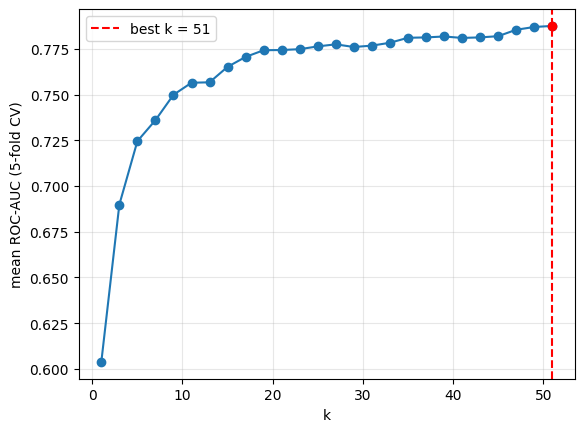

51 0.7875763852415859


In [ ]:
ks = list(range(1, 52, 2))
means = []
for k in ks:
    p = Pipeline([("imp", SimpleImputer(strategy="median")),
                  ("sc",  StandardScaler()),
                  ("knn", KNeighborsClassifier(n_neighbors=k))])
    means.append(cross_val_score(p, X_train[num], y_train, cv=cv, scoring="roc_auc").mean())

best_k = ks[int(np.argmax(means))]
plt.plot(ks, means, marker="o")
plt.axvline(best_k, color="red", ls="--", label=f"best k = {best_k}")
plt.scatter([best_k], [max(means)], color="red", zorder=5)
plt.xlabel("k"); plt.ylabel("mean ROC-AUC (5-fold CV)"); plt.legend(); plt.grid(alpha=.3)
plt.show()
print(best_k, max(means))

In [ ]:
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc",  StandardScaler())]), num),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat),
])
model = Pipeline([("pre", pre), ("knn", KNeighborsClassifier())])

param_grid = {
    "knn__n_neighbors": list(range(1, 52, 2)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],                         # 1 = Manhattan, 2 = Euclidean
}
gs = GridSearchCV(model, param_grid, scoring="roc_auc", cv=cv, n_jobs=-1)
gs.fit(X_train, y_train)
print(gs.best_params_, gs.best_score_)
best = gs.best_estimator_

{'knn__n_neighbors': 49, 'knn__p': 1, 'knn__weights': 'distance'} 0.8064255846488768


In [ ]:
proba = best.predict_proba(X_test)[:, 1]
pred  = (proba >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(confusion_matrix(y_test, pred))
print("Accuracy ", accuracy_score(y_test, pred))
print("Precision", precision_score(y_test, pred))
print("Recall   ", recall_score(y_test, pred))
print("F1       ", f1_score(y_test, pred))
print("ROC-AUC  ", roc_auc_score(y_test, proba))

[[572   8]
 [135  35]]
Accuracy  0.8093333333333333
Precision 0.813953488372093
Recall    0.20588235294117646
F1        0.3286384976525822
ROC-AUC   0.7976926977687626


In [ ]:
TEST_COST = 150   # ASSUMPTION: replace with the real cost per HbA1c test
rows = []
for t in [0.1, 0.2, 0.3, 0.4, 0.5]:
    sel = proba >= t
    n, found = int(sel.sum()), int(y_test.values[sel].sum())
    rows.append([t, n, found, int(y_test.sum()) - found,
                 round(found / n, 3), round(n * TEST_COST / found)])
print(pd.DataFrame(rows, columns=["threshold", "tests", "found", "missed",
                                  "hit_rate", "cost_per_found_₹"]))

   threshold  tests  found  missed  hit_rate  cost_per_found_₹
0        0.1    528    159      11     0.301               498
1        0.2    331    133      37     0.402               373
2        0.3    192     97      73     0.505               297
3        0.4     98     59     111     0.602               249
4        0.5     43     35     135     0.814               184


In [ ]:
order = np.argsort(-proba, kind="stable")
top250 = order[:250]
found = int(y_test.values[top250].sum())
print(found, "of", int(y_test.sum()), "| random expectation:", 250 / 750 * y_test.sum())

115 of 170 | random expectation: 56.666666666666664


In [ ]:
Xt = X_test.reset_index(drop=True); yt = y_test.reset_index(drop=True)
waist_cut = np.where(Xt["sex"] == "Male", 90, 80)
rule = (Xt["age"] >= 45) & (Xt["waist_cm"] >= waist_cut)   # missing age or waist = not selected
n_rule, f_rule = int(rule.sum()), int(yt[rule].sum())
print(n_rule, f_rule, f_rule / n_rule)
print("per ₹1000:", f_rule / (n_rule * TEST_COST) * 1000, found / (250 * TEST_COST) * 1000)

350 118 0.33714285714285713
per ₹1000: 2.2476190476190476 3.066666666666667


In [ ]:
i = [j for j in top250 if y_test.values[j] == 1][0]        # a top-250 visitor (here, a true positive)
pre_fit, knn = best["pre"], best["knn"]
dist, idx = knn.kneighbors(pre_fit.transform(X_test.iloc[[i]]), n_neighbors=5)

print("Visitor:", X_test.iloc[i].to_dict(), "| P(diabetic) =", round(proba[i], 2))
nb = X_train.iloc[idx[0]][["age","sex","waist_cm","bmi","daily_steps","systolic","total_cholesterol"]].copy()
nb["hba1c"] = y_train.iloc[idx[0]].values
print(nb)

Visitor: {'age': 69.0, 'bmi': 33.6, 'waist_cm': 113.0, 'daily_steps': 590.0, 'systolic': 140.0, 'diastolic': 87.0, 'total_cholesterol': 243.0, 'sex': 'Male', 'family_history': 1} | P(diabetic) = 0.79
       age     sex  waist_cm   bmi  daily_steps  systolic  total_cholesterol  \
2538  61.0    Male     115.0  32.6       1480.0     150.0              222.0   
958   55.0    Male     112.0  31.0       2650.0     134.0              248.0   
293   66.0    Male     119.0  34.4       3280.0     134.0              214.0   
1912  64.0    Male     117.0  36.6       7090.0     138.0              235.0   
2885  62.0  Female     116.0  35.4       2420.0     133.0              187.0   

      hba1c  
2538      1  
958       1  
293       1  
1912      1  
2885      1  


In [ ]:
raw = Pipeline([("imp", SimpleImputer(strategy="median")),
                ("knn", KNeighborsClassifier(5))]).fit(X_train[num], y_train)
scl = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
                ("knn", KNeighborsClassifier(5))]).fit(X_train[num], y_train)

def summarise(name, p):
    top = np.argsort(-p, kind="stable")[:250]
    return [name, accuracy_score(y_test, p >= .5), recall_score(y_test, p >= .5),
            roc_auc_score(y_test, p), int(y_test.values[top].sum())]

print(pd.DataFrame([
    summarise("Raw KNN (k=5)",    raw.predict_proba(X_test[num])[:, 1]),
    summarise("Scaled KNN (k=5)", scl.predict_proba(X_test[num])[:, 1]),
    summarise("Tuned KNN",        proba)],
    columns=["model", "accuracy", "recall@0.5", "ROC-AUC", "found in top 250"]))

              model  accuracy  recall@0.5   ROC-AUC  found in top 250
0     Raw KNN (k=5)  0.762667    0.176471  0.656364                81
1  Scaled KNN (k=5)  0.788000    0.341176  0.722510                99
2         Tuned KNN  0.809333    0.205882  0.797693               115
